In [ ]:
# -*- coding: utf-8 -*-

Untitled2.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1EkVxHDvyRca6KQjRAzgXitGShICK1-ma


In [ ]:

import pandas as pd
import numpy as np
dataset=pd.read_csv("/content/Wine dataset.csv")
dataset.head()

dataset.shape

from sklearn import preprocessing
import numpy as np
min_max_scaler=preprocessing.MinMaxScaler()
x_scale=min_max_scaler.fit_transform(dataset)
scaled_dataset=pd.DataFrame(x_scale,columns=dataset.columns)
scaled_dataset.head()

num_classes = dataset['class'].nunique()
print(f"Number of unique classes in the 'class' column: {num_classes}")

from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

# Separate features (X) and target (y)
X = scaled_dataset.drop('class', axis=1)
y = scaled_dataset['class']

# One-hot encode the target variable
y_encoded = to_categorical(y - 1, num_classes=num_classes) # Subtract 1 if classes are 1, 2, 3 to make them 0, 1, 2

x_train, x_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=0, stratify=y)

from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense
model=Sequential()
model.add(Dense(12,input_dim=x_train.shape[1],activation='relu')) # Adjusted input_dim
model.add(Dense(8,activation='relu'))
model.add(Dense(num_classes,activation='softmax')) # Changed to num_classes and softmax for multi-class
model.compile(loss='categorical_crossentropy',optimizer='adam',metrics=['accuracy'])
model.fit(x_train,y_train,epochs=15,batch_size=11)

y_pred=model.predict(x_test)

Number of unique classes in the 'class' column: 3
Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0141 - loss: 1.1560    
Epoch 2/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2676 - loss: 1.0963 
Epoch 3/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4859 - loss: 1.0430 
Epoch 4/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4718 - loss: 0.9900 
Epoch 5/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5352 - loss: 0.9371 
Epoch 6/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6268 - loss: 0.8825 
Epoch 7/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7465 - loss: 0.8256 
Epoch 8/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9296 - loss: 0.7693 
Epoch 9/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7746 - loss: 0.7213 
Epoch 10/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6690 - loss: 0.6844 
Epoch 11/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6690 - loss: 0.6536 
Epoch 12/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6690 -

The previous lines for `np.where` and `astype(int)` were incorrect for multi-class classification
y_pred will now contain the raw probabilities for each class
np.column_stack((y_pred,y_test)) # This line was also problematic for direct comparison


Confusion Matrix:
[[24  0]
 [ 4  8]]

Accuracy Score:
0.8888888888888888


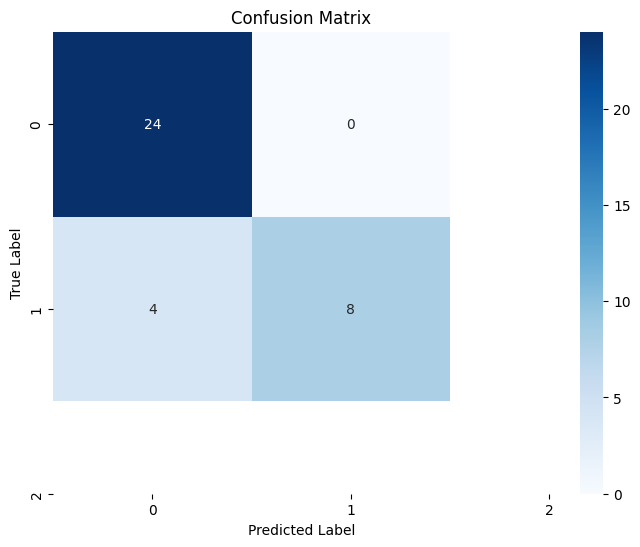

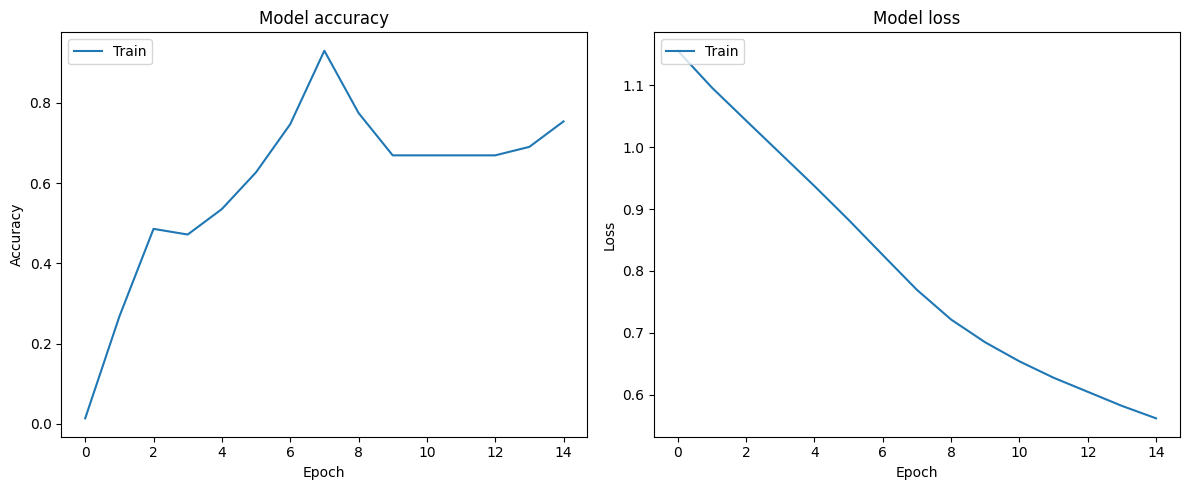

In [ ]:

from sklearn.metrics import accuracy_score,confusion_matrix
import numpy as np

# Convert one-hot encoded y_test to class labels
y_test_classes = np.argmax(y_test, axis=1)

# Convert one-hot encoded y_pred to class labels
y_pred_classes = np.argmax(y_pred, axis=1)

print("Confusion Matrix:")
print(confusion_matrix(y_test_classes, y_pred_classes))

print("\nAccuracy Score:")
print(accuracy_score(y_test_classes, y_pred_classes))

import matplotlib.pyplot as plt
import seaborn as sns
# Create a heatmap of the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test_classes, y_pred_classes), annot=True, fmt='d', cmap='Blues',
            xticklabels=np.arange(num_classes), yticklabels=np.arange(num_classes))
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Plot training & validation accuracy values
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(model.history.history['accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(model.history.history['loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train'], loc='upper left')
plt.tight_layout()
plt.show()